# Detector de *Aedes aegypti* pelo som — demo

O caminho completo de um projeto de ML, em poucas células:

1. **Dados**: cada gravação vira 80 números (16 faixas de frequência × 5 resumos).
2. **Preparo**: normalizar por fonte e dar o mesmo peso a cada fonte.
3. **Modelo**: duas etapas com árvores (*tem mosquito?* → *é Aedes?*).
4. **Prova**: validação cruzada por grupo (gravação/aparelho nunca visto).
5. **Avaliação**: matriz de confusão, curva ROC e escolha do limiar.
6. **Interpretação**: em quais frequências o modelo presta atenção.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
CLASSES = ['ruído', 'outro mosquito', 'Aedes']

## 1. Dados
Cada linha é uma gravação: 80 atributos `X`, a classe `y` (0 = ruído, 1 = outro mosquito, 2 = Aedes), a **fonte** e o **grupo** (gravação/aparelho).

In [2]:
dados = np.load(Path('../experimento_mistura/pool.npz'), allow_pickle=True)
X, y, fonte, grupo = dados['X'], dados['y'], dados['src'], dados['grp'].astype(object)

# Funchal: o grupo é o aparelho (taxa de amostragem da pasta)
f = fonte == 'funchal'
grupo[f] = ['funchal:' + ('8k' if '8khz' in g else '44k' if '44.1khz' in g else '48k') for g in grupo[f]]

# Aedes só do Torres e do Funchal; as outras fontes entram só com não-Aedes
usar = ((y == 2) & np.isin(fonte, ['torres', 'funchal'])) | (y < 2)
X, y, fonte, grupo = X[usar], y[usar], fonte[usar], grupo[usar]
print(X.shape, '-> gravações × atributos')
for c, nome in enumerate(CLASSES):
    print(f'{nome:15s}', (y == c).sum())

(5643, 80) -> gravações × atributos
ruído           426
outro mosquito  3050
Aedes           2167


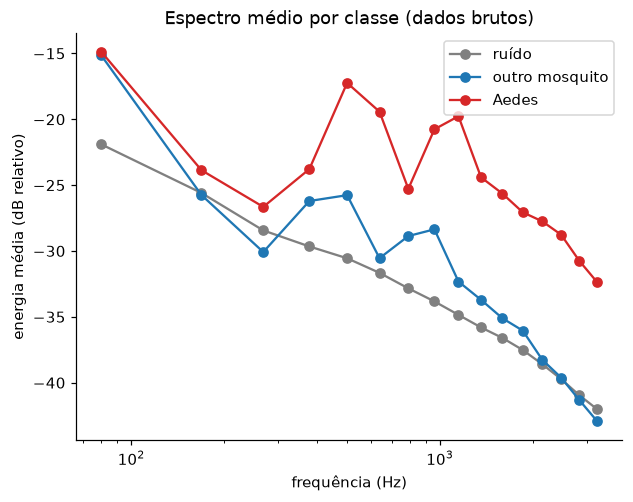

In [3]:
# Como é o "espectro médio" de cada classe? (média de energia em cada uma das 16 faixas)
# Atenção: parte da diferença vem do aparelho de cada fonte, não do mosquito; por isso normalizamos depois.
centros = [80, 169, 268, 378, 501, 638, 791, 961, 1150, 1361, 1596, 1858, 2149, 2474, 2836, 3240]
for c, cor in zip([0, 1, 2], ['gray', 'tab:blue', 'tab:red']):
    plt.plot(centros, X[y == c, :16].mean(0), 'o-', color=cor, label=CLASSES[c])
plt.xscale('log'); plt.xlabel('frequência (Hz)'); plt.ylabel('energia média (dB relativo)')
plt.legend(); plt.title('Espectro médio por classe (dados brutos)'); plt.show()

## 2. Preparo
**Normalizar por fonte** tira o "sotaque" de cada microfone. **Pesos por fonte** impedem que a fonte com mais exemplos domine o treino.

In [4]:
def normalizar_por_fonte(X, fonte):
    Xn = X.copy()
    for s in np.unique(fonte):
        m = fonte == s
        Xn[m] = (X[m] - X[m].mean(0)) / (X[m].std(0) + 1e-6)
    return Xn

def pesos_por_fonte(y, fonte):
    w = np.ones(len(y))
    for c in np.unique(y):
        fontes_c = np.unique(fonte[y == c])
        for s in fontes_c:
            m = (y == c) & (fonte == s)
            w[m] = 1 / m.sum() / len(fontes_c)
    return w / w.mean()

Xn = normalizar_por_fonte(X, fonte)

## 3. Modelo em duas etapas + 4. prova por grupo
Etapa 1: *tem mosquito?* Etapa 2 (só entre mosquitos): *é Aedes?* — média de HistGB e Extra Trees. Leva cerca de 1 minuto.

In [5]:
def hgb():   # boosting: árvores em fila
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                          l2_regularization=1.0, min_samples_leaf=12, random_state=11)
def floresta():   # Extra Trees: árvores independentes que votam
    return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=11)

def treinar_e_prever(tr, te):
    y1 = (y[tr] > 0).astype(int)                         # etapa 1: tem mosquito?
    p_mosq = hgb().fit(Xn[tr], y1, sample_weight=pesos_por_fonte(y1, fonte[tr])).predict_proba(Xn[te])[:, 1]

    mos = tr[y[tr] > 0]; y2 = (y[mos] == 2).astype(int)  # etapa 2: entre mosquitos, é Aedes?
    w2 = pesos_por_fonte(y2, fonte[mos])
    p_aedes = (hgb().fit(Xn[mos], y2, sample_weight=w2).predict_proba(Xn[te])[:, 1]
               + floresta().fit(Xn[mos], y2, sample_weight=w2).predict_proba(Xn[te])[:, 1]) / 2
    return np.c_[1 - p_mosq, p_mosq * (1 - p_aedes), p_mosq * p_aedes]   # [ruído, outro, Aedes]

P = np.zeros((len(y), 3))
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=11).split(Xn, y, grupo):
    assert not set(grupo[tr]) & set(grupo[te]), 'vazamento: o mesmo grupo no treino e na prova!'
    P[te] = treinar_e_prever(tr, te)
print('pronto: cada gravação recebeu uma previsão de um modelo que nunca a viu')

pronto: cada gravação recebeu uma previsão de um modelo que nunca a viu


## 5. Avaliação
### Matriz de confusão
Linhas = o que era de verdade; colunas = o que o modelo disse.

precisão  = 78%   (quando diz Aedes, acerta)
detecção  = 46%   (dos Aedes, quantos achou)


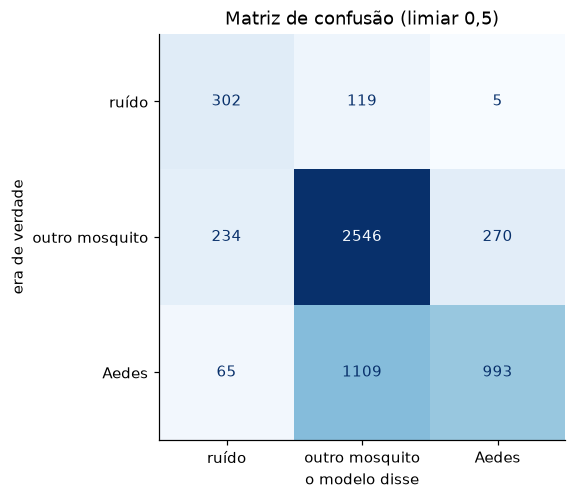

In [6]:
limiar = 0.5
pred = np.where(P[:, 2] > limiar, 2, P[:, :2].argmax(1))
cm = confusion_matrix(y, pred)
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap='Blues', colorbar=False)
disp.ax_.set_xlabel('o modelo disse'); disp.ax_.set_ylabel('era de verdade')
plt.title('Matriz de confusão (limiar 0,5)'); plt.show()

vp, fp = cm[2, 2], cm[0, 2] + cm[1, 2]
print(f'precisão  = {vp / (vp + fp):.0%}   (quando diz Aedes, acerta)')
print(f'detecção  = {vp / cm[2].sum():.0%}   (dos Aedes, quantos achou)')

### Curva ROC
Cada ponto é um limiar diferente: quanto mais a curva sobe pela esquerda, melhor. A área sob a curva é o **AUROC** (0,5 = moeda).

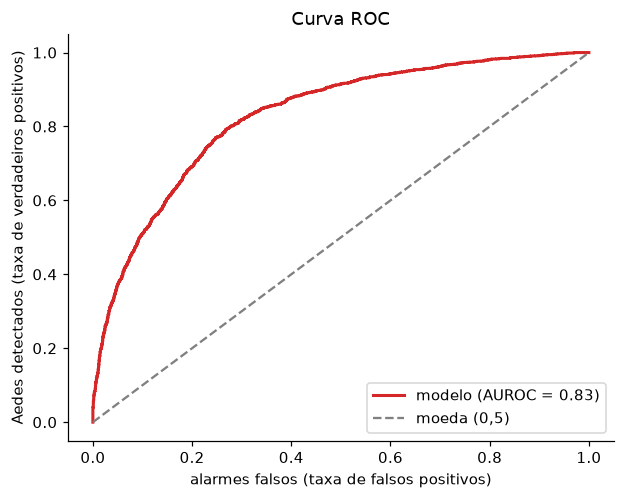

In [7]:
eh_aedes = y == 2
fpr, tpr, _ = roc_curve(eh_aedes, P[:, 2])
plt.plot(fpr, tpr, color='tab:red', lw=2, label=f'modelo (AUROC = {roc_auc_score(eh_aedes, P[:, 2]):.2f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='moeda (0,5)')
plt.xlabel('alarmes falsos (taxa de falsos positivos)'); plt.ylabel('Aedes detectados (taxa de verdadeiros positivos)')
plt.legend(); plt.title('Curva ROC'); plt.show()

### Escolhendo o limiar
O modelo dá uma **nota** de 0 a 1. Onde cortar é uma decisão de projeto: mais detecção custa mais alarme falso.

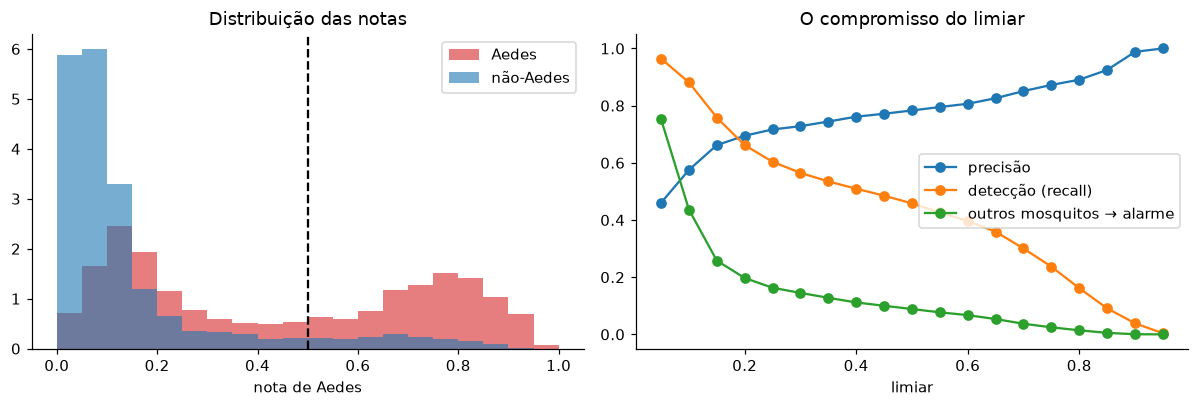

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0, 1, 21)
ax[0].hist(P[y == 2, 2], bins, alpha=.6, color='tab:red', label='Aedes', density=True)
ax[0].hist(P[y < 2, 2], bins, alpha=.6, color='tab:blue', label='não-Aedes', density=True)
ax[0].axvline(limiar, color='k', ls='--'); ax[0].set_xlabel('nota de Aedes'); ax[0].legend(); ax[0].set_title('Distribuição das notas')

ts = np.linspace(0.05, 0.95, 19)
ax[1].plot(ts, [eh_aedes[P[:, 2] > t].mean() for t in ts], 'o-', label='precisão')
ax[1].plot(ts, [(P[eh_aedes, 2] > t).mean() for t in ts], 'o-', label='detecção (recall)')
ax[1].plot(ts, [(P[y == 1, 2] > t).mean() for t in ts], 'o-', label='outros mosquitos → alarme')
ax[1].set_xlabel('limiar'); ax[1].legend(); ax[1].set_title('O compromisso do limiar')
plt.tight_layout(); plt.show()

## 6. Interpretação: em quais frequências o modelo presta atenção?
Embaralhamos uma faixa por vez no teste e medimos quanto o AUROC cai (resultado pré-calculado em `interpretabilidade_final.py`).

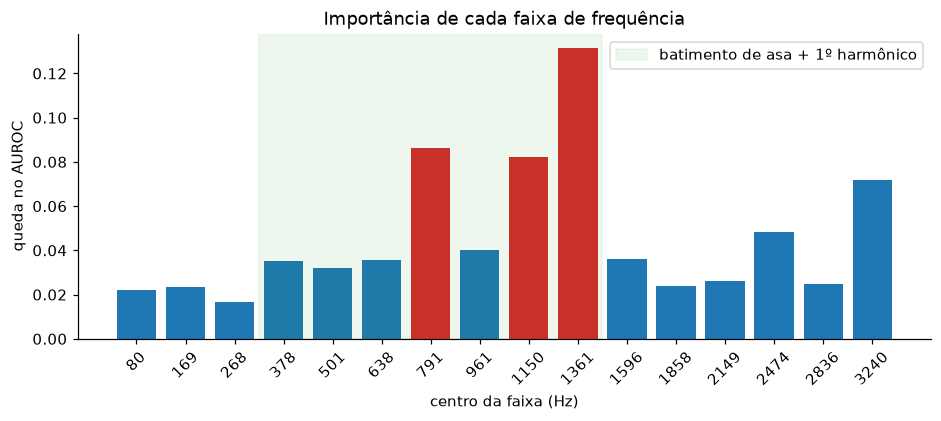

In [9]:
import json
imp = json.load(open('../experimento_mistura/interpretabilidade_final.json'))
quedas = [b['queda_auroc'] for b in imp['bandas']]
cores = ['tab:red' if q >= sorted(quedas)[-3] else 'tab:blue' for q in quedas]
plt.figure(figsize=(10, 3.6))
plt.bar([str(c) for c in centros], quedas, color=cores)
plt.axvspan(2.5, 9.5, color='tab:green', alpha=.08, label='batimento de asa + 1º harmônico')
plt.xticks(rotation=45); plt.xlabel('centro da faixa (Hz)'); plt.ylabel('queda no AUROC'); plt.legend()
plt.title('Importância de cada faixa de frequência'); plt.show()